Name Taherunnesa Rahi

Labpartner(s)

In [1]:
#import statements go here
import pandas as pd
import matplotlib.pyplot as plt

# Class 8.2

Today we are having a guest lecture online by [Will Faulkner](https://www.linkedin.com/in/wnfaulkner/) on "vibe coding" aka the use of LLMs to build code when you have no or little idea what you are doing. 

**W.1** This week our warmups are focused on applying your Pandas skills. Please continue your analysis of the 2026 World Cup player stats from slack (pinned to #announcements). Make sure you write some text about what you found. 

In [2]:
data=pd.read_csv("player_stats.csv")

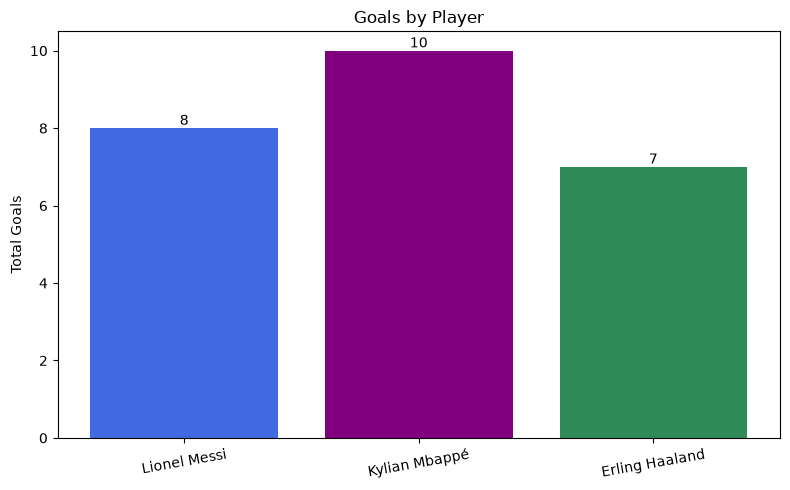

In [8]:
#how to find players information when i dont know the full name
players = ["Lionel Messi", "Kylian Mbappé", "Erling Haaland"]
search_words = ["Messi", "Mbapp", "Haaland"]
goal_totals = []

for word in search_words:
    total = data.loc[
        data["player_name"].str.contains(word, case=False, na=False),
        "goals"
    ].sum()
    goal_totals.append(total)

plt.figure(figsize=(8, 5))
bars = plt.bar(players, goal_totals, color=["royalblue", "purple", "seagreen"])

plt.title("Goals by Player")
plt.ylabel("Total Goals")
plt.xticks(rotation=10)

# Show the goal total above each bar
plt.bar_label(bars)
plt.tight_layout()
plt.show()

In [ ]:
I found that Kylian Mbappe scored the most goals.

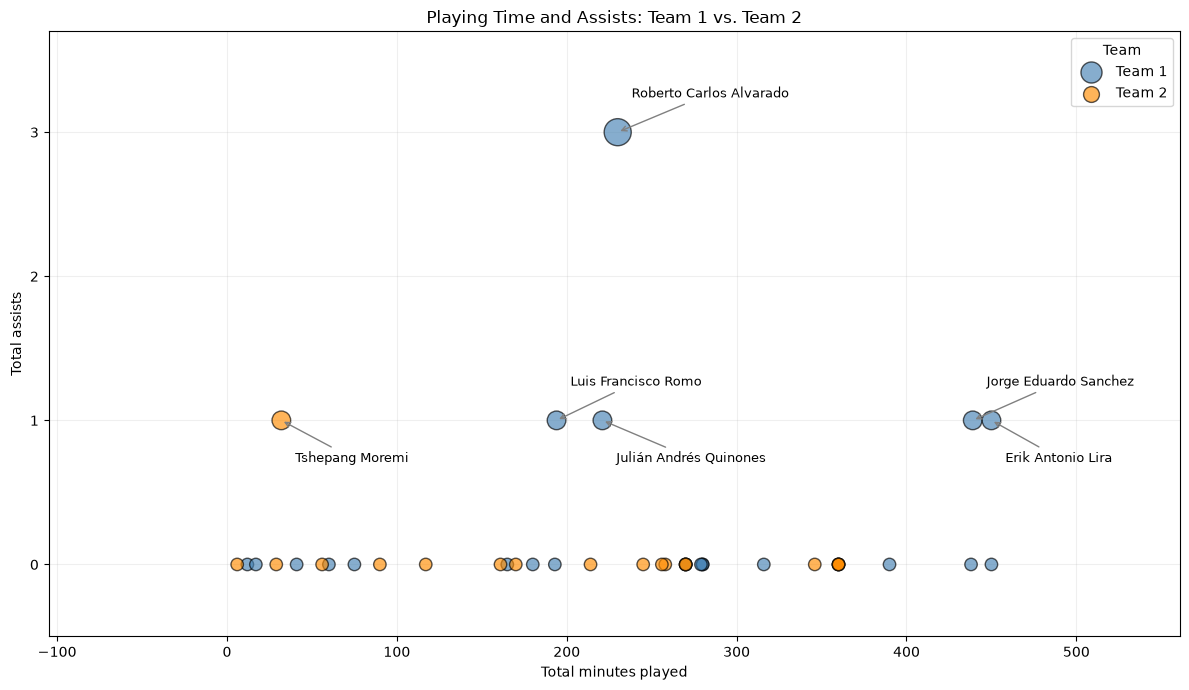

In [9]:
# Which players from teams 1 and 2 provided more assists with less playing time?

data = pd.read_csv("player_stats.csv")

# Select players from teams 1 and 2 who played
selected = data[
    data["team_id"].isin([1, 2])
    & (data["minutes_played"] > 0)
].dropna(subset=["minutes_played", "assists"]).copy()

fig, ax = plt.subplots(figsize=(12, 7))

colors = {1: "steelblue", 2: "darkorange"}

# Plot each team
for team in [1, 2]:
    team_data = selected[selected["team_id"] == team]

    ax.scatter(
        team_data["minutes_played"],
        team_data["assists"],
        s=80 + team_data["assists"] * 100,
        color=colors[team],
        alpha=0.65,
        edgecolors="black",
        label=f"Team {team}"
    )

# Label players with at least one assist
contributors = selected[selected["assists"] > 0]

for i, (_, row) in enumerate(contributors.iterrows()):
    ax.annotate(
        row["player_name"],
        xy=(row["minutes_played"], row["assists"]),
        xytext=(10, 25 if i % 2 == 0 else -30),
        textcoords="offset points",
        fontsize=9,
        arrowprops=dict(arrowstyle="->", color="gray")
    )

ax.set_xlabel("Total minutes played")
ax.set_ylabel("Total assists")
ax.set_title("Playing Time and Assists: Team 1 vs. Team 2")

# Use whole numbers for assists
ax.set_yticks(range(int(selected["assists"].max()) + 1))
ax.set_ylim(-0.5, selected["assists"].max() + 0.7)
ax.margins(x=0.25)

ax.legend(title="Team")
ax.grid(alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

I found that Roberto Carlos from team 1 made more assists than others.

# Lecture 8.2

### Agenda: Will will talk about vibe coding, we'll have a break, and then he'll share some examples


### Questions

# Lab 8.2

**E.0** Complete the previous labs if you are behind.

**E.1** "Vibe coding" in practice, part 1. Take a dataset of your choice and use an LLM to do some kind of manipulation or analysis of that data. You should focus on trying something that you couldn't easily figure out on your own. Paste the resulting code and results here.

In [9]:
canopy=pd.read_csv("Hillcrest_canopy.csv")
canopy.head()

,Location,ID,CanopyCover(%),Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11
0,"30.58488816080309, -91.13174951135768",BVWVOpenR5,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"30.585142849454336, -91.13199904968813",BVWVShadeR5,81.75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"30.585049357005126, -91.13225688304425",BVWVOpenR4,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Sample deployment date: 5/8/2026
3,"30.584875475556604, -91.13282248001785",BVOVShadeR4,83.75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"30.58427793918678, -91.13029138737615",BVOVShadeR3,89.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
vase_data=pd.read_csv("Hillcrest_data collection_including_culex.csv")
vase_data.head()

,Sample ID,Collection date,Water Temperature (degree C),emerging date,Number of Mosquitoes,Species
0,BVOpenR5,5/16/2026,33.4,NaN,NaN,NaN
1,WVOpenR5,5/16/2026,31.5,NaN,NaN,NaN
2,BVShadeR5,5/16/2026,28.8,NaN,NaN,NaN
3,WVShadeR5,5/16/2026,28.4,NaN,NaN,NaN
4,BVOpenR4,5/16/2026,32.2,NaN,NaN,NaN


In [13]:
vase_data["merge_key"] = (
    vase_data["Sample ID"].str.extract(
        r"((?:OPEN|SHADE)\s*R\s*\d+)", expand=False
    )
    .str.replace(r"\s+", "", regex=True)
    .str.upper()
)

canopy["merge_key"] = (
    canopy["ID"].str.extract(
        r"((?:OPEN|SHADE)\s*R\s*\d+)", expand=False
    )
    .str.replace(r"\s+", "", regex=True)
    .str.upper()
)

vase_data["Sample ID"] selects the sample ID column.
.str.extract(...) finds either OPEN or SHADE, followed by R and the replicate number.
For example, it extracts OpenR5 from BVOpenR5.
.str.replace(...) removes any spaces in the extracted text.
.str.upper() changes it to uppercase: OPENR5.
vase_data["merge_key"] = saves that result in a new column called merge_key.

- r — tells Python to treat the backslashes as written, so the regular expression can use symbols like \s and \d.
- The quotation marks — mark the beginning and end of the pattern.
- The outer parentheses ( ... ) — mark the text to return as the match.
- (?:OPEN|SHADE) — match either OPEN or SHADE.
  - (?: ... ) groups the choices.
  - | means “or.”
- \s* — match zero or more spaces. This allows the ID to have spaces there, or none.
- R — match the letter R.
- Another \s* — allow zero or more spaces after R.
- \d+ — match one or more digits. This finds the replicate number, such as 5.
So the pattern finds text like OpenR5 or ShadeR4 inside an ID.

In [14]:
print(vase_data[["Sample ID", "merge_key"]].drop_duplicates())
print(canopy[["ID", "merge_key"]].drop_duplicates())

    Sample ID merge_key
0    BVOPENR5    OPENR5
1    WVOPENR5    OPENR5
2   BVSHADER5   SHADER5
3   WVSHADER5   SHADER5
4    BVOPENR4    OPENR4
5    WVOPENR4    OPENR4
6   BVSHADER4   SHADER4
7   WVSHADER4   SHADER4
8    BVOPENR3    OPENR3
9    WVOPENR3    OPENR3
10  BVSHADER3   SHADER3
11  WVSHADER3   SHADER3
12   BVOPENR2    OPENR2
13   WVOPENR2    OPENR2
14  BVSHADER2   SHADER2
15  WVSHADER2   SHADER2
16   BVOPENR1    OPENR1
17   WVOPENR1    OPENR1
18  BVSHADER1   SHADER1
19  WVSHADER1   SHADER1
            ID merge_key
0   BVWVOPENR5    OPENR5
1  BVWVSHADER5   SHADER5
2   BVWVOPENR4    OPENR4
3  BVOVSHADER4   SHADER4
4  BVOVSHADER3   SHADER3
5   BVOVOPENR3    OPENR3
6  BVWVSHADER2   SHADER2
7   BVWVOPENR2    OPENR2
8  BVWVSHADER1   SHADER1
9   BVOVOPENR1    OPENR1


In [15]:
combined_data = vase_data.merge(
    canopy[["merge_key", "CanopyCover(%)"]],
    on="merge_key",
    how="left",
    validate="many_to_one"
)

# Check the combined dataset
combined_data.head()
combined_data.to_csv("Hillcrest_vase_data_with_canopy.csv", index=False)

**E.2** "Vibe coding" in practice, part 2. Now take the same data set and make some kind of plot, again focusing on something that would be difficult to figure out on your own. Paste the resulting code and results here.

In [16]:
combined_data.head()

,Sample ID,Collection date,Water Temperature (degree C),emerging date,Number of Mosquitoes,Species,merge_key,CanopyCover(%)
0,BVOPENR5,5/16/2026,33.4,NaN,NaN,NaN,OPENR5,0.00
1,WVOPENR5,5/16/2026,31.5,NaN,NaN,NaN,OPENR5,0.00
2,BVSHADER5,5/16/2026,28.8,NaN,NaN,NaN,SHADER5,81.75
3,WVSHADER5,5/16/2026,28.4,NaN,NaN,NaN,SHADER5,81.75
4,BVOPENR4,5/16/2026,32.2,NaN,NaN,NaN,OPENR4,0.00


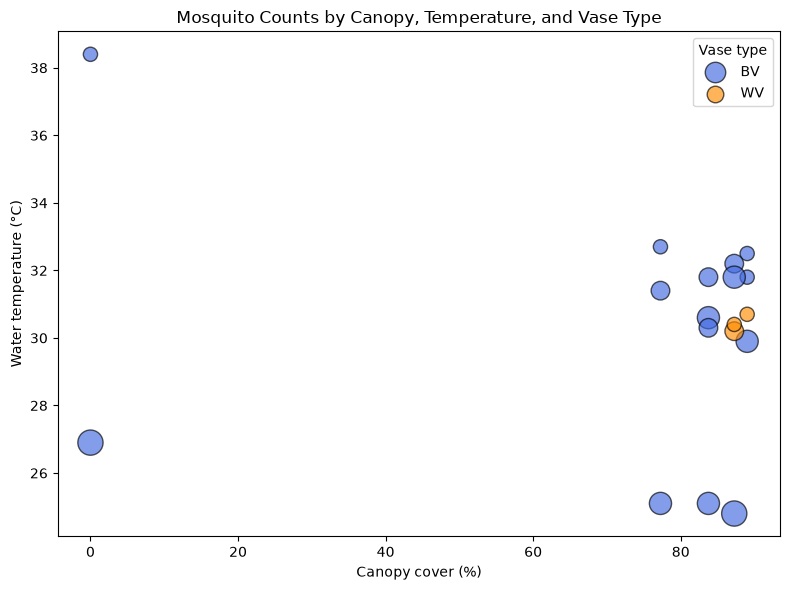

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

plot_data = combined_data.copy()

plot_data["count"] = pd.to_numeric(
    plot_data["Number of Mosquitoes"], errors="coerce"
)
plot_data["temperature"] = pd.to_numeric(
    plot_data["Water Temperature (degree C)"], errors="coerce"
)
plot_data["canopy"] = pd.to_numeric(
    plot_data["CanopyCover(%)"], errors="coerce"
)
plot_data["vase_type"] = (
    plot_data["Sample ID"].astype("string").str.strip().str[:2].str.upper()
)

plot_data = plot_data.dropna(
    subset=["count", "temperature", "canopy", "vase_type"]
)

# Scale bubble sizes so they fit the plot
max_count = plot_data["count"].max()
size_scale = 300 / max_count if max_count > 0 else 0

fig, ax = plt.subplots(figsize=(8, 6))

vase_colors = {"BV": "royalblue", "WV": "darkorange"}

for vase_type, color in vase_colors.items():
    group = plot_data[plot_data["vase_type"] == vase_type]
    ax.scatter(
        group["canopy"],
        group["temperature"],
        s=30 + group["count"] * size_scale,
        color=color,
        alpha=0.65,
        edgecolor="black",
        label=vase_type
    )

ax.set_xlabel("Canopy cover (%)")
ax.set_ylabel("Water temperature (°C)")
ax.set_title("Mosquito Counts by Canopy, Temperature, and Vase Type")
ax.legend(title="Vase type")
plt.tight_layout()
plt.show()

**E.3** Now let's think, does your use of AI in the examples above fit into Wiley's best practices framework? What are the dangers and oppertunities here? Use specific examples from the Wiley resources and relate them to your workflow above:

https://www.wiley.com/en-us/publishing/book/ai-guidelines

https://www.wiley.com/en-us/publishing/article/ai-guidelines

Specifically, when is it ethical to use AI for research, and when is it not? When is it in your best interest as a student to use AI, and when is it not? What are the enviornmental considerations of using AI? How might you use AI in your final project in line with ethical guidelines? You should be writng a few paragraphs at minimum with examples here. 


I used AI to write Python code to merge data from two CSV files and make the plot. Wiley mentions code generation and debugging in its “Types of AI tools” section, so using AI for coding fits here. 
The opportunities are that I can save time and focus on analysis rather than coding. The dangers are that if I do not know basic coding, it can hamper my results; for example, if any piece of code manipulates my original data without my supervision.
It is ethical to use AI if I use it for polishing my writing, coding, and debugging. It is also ethical to search literature, but the literature should be double-checked because AI may give wrong literature or fake references. It is not ethical to give AI the ownership of your writing. A writer needs to be the owner of the content and responsible for his content. AI can be used as a companion, but it needs to be under supervision. 
AI has environmental impacts in terms of producing greenhouse gases through fossil fuel burning while generating the electricity it uses. AI also uses water for cooling; it can impact water-stressed watersheds. 
I can use it for correcting my code syntax in my project. It is under the ethical use of AI category.

**E.4** Make notes for yourself on progamming tecniques and commands you learned in the this week, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.

.str.contains()
example data["player_name"].str.contains("Messi", case=False, na=False)
I can search using part of a name. It ignores capitalization and treats missing names as no match.

.isin() and &
example data[data["team_id"].isin([1, 2]) & (data["minutes_played"] > 0)]
Keeps players from teams 1 and 2 who played more than zero minutes.

dropna()	
example selected.dropna(subset=["assists", "minutes_played"])	
Removes rows missing assists or playing time

ax.annotate("Player", xy=(200, 1), xytext=(250, 2), arrowprops=dict(arrowstyle="->"))
add arrow


.str.extract()
vase_data["Sample ID"].str.extract(r"((?:OPEN|SHADE)\s*R\s*\d+)", expand=False)
Pulls out a sample label such as OPEN R5 or SHADE R2.

.merge()
vase_data.merge(canopy[["merge_key", "CanopyCover(%)"]], on="merge_key", how="left", validate="many_to_one")
Adds matching canopy information while keeping all vase rows.


errors="coerce" if a value cannot be converted into a number, replace it with NaN, meaning missing.